# 1 · Un modelo en un notebook

<a href="https://colab.research.google.com/github/B3njjaman/MLOps-en-Azure/blob/main/modulos/modulo-1/01_un_modelo_en_un_notebook.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"></a>

**Módulo 1 · Del notebook al código reproducible.** El proyecto del curso es el pronóstico diario del consumo eléctrico de una planta industrial. Esta lección construye el primer modelo como se construye casi siempre: en un notebook, de arriba abajo. Corre en Colab, en Kaggle o en el PC, en CPU y sin claves.

La lección parte del contrato del pronóstico: qué decisión apoya, a qué hora se necesita y con qué datos cuenta a esa hora. Después presenta la planta, que es simulada: como se conoce el proceso que genera sus datos, se puede dejar que el tiempo avance y medir cuánto se equivoca el modelo en días que nunca vio. El modelo del notebook promete un error medio de 6,1 MWh. En 2026 la planta sigue funcionando y el modelo entrega 9,0. El resto de la lección busca de dónde sale esa diferencia y encuentra cuatro fallas. Cada una es el tema de una lección de este módulo.

Requisitos: numpy, pandas, scikit-learn y matplotlib, que Colab y Kaggle ya traen. La primera celda descarga el simulador de la planta si no está junto al notebook. Las cifras del texto salen de scikit-learn 1.9 y pandas 3.1. Con otras versiones, como las de Colab, algunas cambian en el último decimal (la lección 2 explica por qué).

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

if not Path("planta.py").exists():  # en Colab o Kaggle; en el PC ya está junto al notebook
    urlretrieve(
        "https://raw.githubusercontent.com/B3njjaman/MLOps-en-Azure/main/modulos/modulo-1/planta.py",
        "planta.py",
    )

from importlib.metadata import version

for paquete in ("numpy", "pandas", "scikit-learn", "matplotlib"):
    print(paquete, version(paquete))

numpy 2.4.6
pandas 3.1.0
scikit-learn 1.9.1
matplotlib 3.11.2


## 1. El pronóstico como contrato

Un modelo en producción existe para apoyar una decisión. Antes de escribir código conviene fijar por escrito qué decide, cuándo y con qué. La planta del curso consume cerca de 280 MWh en un día normal, y cada mañana el equipo de operación programa los equipos de alto consumo y estima la energía que tiene que comprar. Para eso necesita el pronóstico del día a las 06:00.

| | |
|---|---|
| **Decisión** | Programar los equipos de alto consumo y la energía que se compra en el día |
| **Salida** | Consumo eléctrico del día, en MWh |
| **Cuándo** | Todos los días a las 06:00 |
| **Con qué** | Lo que existe a las 06:00: el consumo de los días cerrados, el plan de producción, el calendario y el pronóstico de temperatura |
| **Métrica** | Error absoluto medio (MAE), en MWh |
| **Línea base** | El consumo del mismo día de la semana anterior. Si el modelo no le gana, no se usa |

La fila **Con qué** es la que más se olvida, y la que más cuesta cuando se olvida:

<img src="https://b3njjaman.github.io/MLOps-en-Azure/imagenes/diagramas/modulo-1/seis-de-la-manana.svg" alt="Tres columnas para el día t. Hasta ayer: el consumo de hace 7 días, el de ayer y el pronóstico de temperatura. Hoy a las 06:00: la producción planificada, el calendario y el pronóstico del modelo, ŷ(t) = f(x(t)). Hoy a las 24:00: la temperatura real, el consumo real y el error del día. La animación enciende primero lo que se conoce antes de las 06:00, después el pronóstico, y al final lo que llega a las 24:00" width="860">

**Definición 1.1 (información disponible).** Para el día $t$, $\mathcal{I}_t$ es el conjunto de datos que existen a las 06:00 de ese día: los consumos $y_s$ de los días cerrados $s < t$, la producción planificada $p_t$, el calendario y el pronóstico de temperatura $\hat\tau_t$. La temperatura real $\tau_t$ y el consumo $y_t$ no están en $\mathcal{I}_t$: se conocen a las 24:00.

**Definición 1.2 (pronóstico).** Un pronóstico es una función $f$ que a cada día le asigna $\hat y_t = f(x_t)$, donde el vector de features $x_t$ se calcula solo con datos de $\mathcal{I}_t$.

La condición sobre $x_t$ parece obvia y es fácil de romper: basta con usar una columna de la tabla histórica que a las 06:00 todavía no existe. La sección 5.3 muestra un caso.

## 2. La planta

**Definición 1.3 (la planta).** Para cada día $t = 0, 1, 2, \dots$, contado desde el 1 de enero de 2022, con $d(t)$ el día del año y $x^+ = \max(x, 0)$:

$$\tau_t = 14 + 7\cos\!\left(\frac{2\pi\,(d(t) - 15)}{365{,}25}\right) + a_t, \qquad a_t = 0{,}7\,a_{t-1} + \xi_t,$$

$$\hat\tau_t = \tau_t + \zeta_t,$$

$$y_t = 60 + 0{,}07\,p_t + 4\,(\tau_t - 16)^+ + 3\,(10 - \tau_t)^+ + 0{,}02\,t + u_t, \qquad u_t = 0{,}6\,u_{t-1} + \varepsilon_t,$$

con $\xi_t \sim N(0, 1{,}6^2)$, $\zeta_t \sim N(0, 2^2)$ y $\varepsilon_t \sim N(0, 5^2)$ independientes. La producción planificada $p_t$ es de 3000 t de lunes a sábado y de 2300 t el domingo, con un ruido $N(0, 60^2)$, y baja a unas 400 t en dos paradas de mantención al año, de 6 días cada una, desde el 10 de abril y desde el 2 de octubre.

Cada término tiene una lectura física:

- $\tau_t$ es la temperatura media del día. El coseno tiene su máximo a mediados de enero, el verano del hemisferio sur, y $a_t$ agrega días más fríos o más cálidos que el promedio de la fecha.
- $\hat\tau_t$ es el pronóstico de temperatura publicado la tarde anterior, que se equivoca con una desviación estándar de 2 °C.
- $0{,}07\,p_t$: cada tonelada producida consume 70 kWh. Es el término que más pesa, unos 210 MWh en un día normal.
- $4\,(\tau_t - 16)^+$ y $3\,(10 - \tau_t)^+$: la refrigeración sobre 16 °C y la calefacción bajo 10 °C. Entre 10 y 16 °C la temperatura no influye.
- $0{,}02\,t$: el desgaste de los equipos sube el consumo unos 7,3 MWh por año.
- $u_t$ es lo que ninguna feature explica. Es un proceso AR(1): un día alto tiende a seguir a otro día alto, y la correlación entre días seguidos es 0,6. La sección 5.2 muestra por qué importa.

Los datos son sintéticos a propósito. Con datos reales no se sabe qué error va a tener el modelo en el futuro: hay que esperarlo. Con la planta simulada el futuro ya está escrito, y se puede comparar lo que promete cada forma de evaluar con lo que después pasa.

In [2]:
from planta import historia

df = historia()
df

,fecha,produccion,temperatura_pronostico,temperatura,consumo
0,2022-01-01,3040,21.2,20.8,295.5
1,2022-01-02,2385,21.3,21.3,248.7
2,2022-01-03,2963,18.8,20.7,288.0
3,2022-01-04,2946,20.5,19.4,289.8
4,2022-01-05,3087,15.0,19.1,292.6
...,...,...,...,...,...
1456,2025-12-27,3039,24.1,22.0,333.5
1457,2025-12-28,2229,22.9,24.2,281.1
1458,2025-12-29,3017,18.7,21.5,336.8
1459,2025-12-30,3031,19.3,21.6,323.9


`historia()` entrega los cuatro años que hay para entrenar, de 2022 a 2025: 1461 días. Las columnas son las de la Definición 1.3: `produccion` es $p_t$, `temperatura_pronostico` es $\hat\tau_t$, `temperatura` es $\tau_t$ y `consumo` es $y_t$. La tabla tiene las dos temperaturas porque es un registro histórico, armado después de que cada día terminó.

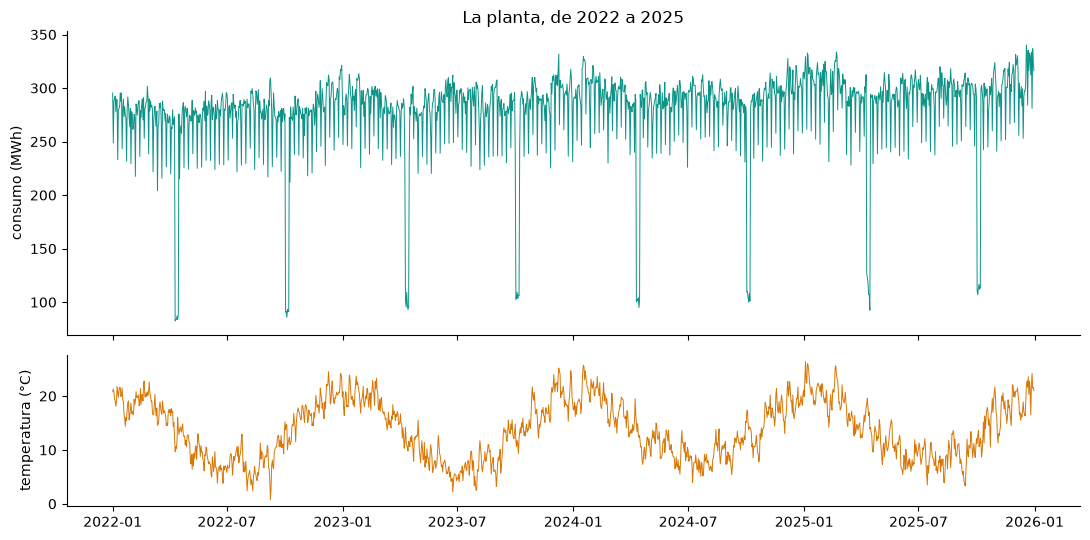

In [3]:
import matplotlib.pyplot as plt

TURQUESA, VIOLETA, AMBAR, ROSA, GRIS = "#0d9488", "#7c3aed", "#d97706", "#e11d48", "#57606a"

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, height_ratios=[2, 1])
ax1.plot(df["fecha"], df["consumo"], lw=0.7, color=TURQUESA)
ax1.set_ylabel("consumo (MWh)")
ax1.set_title("La planta, de 2022 a 2025")
ax2.plot(df["fecha"], df["temperatura"], lw=0.7, color=AMBAR)
ax2.set_ylabel("temperatura (°C)")
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Se ven las fuentes de variación de la Definición 1.3: las paradas de abril y octubre, que bajan el consumo a menos de 130 MWh; la temperatura, que lo sube en verano y un poco en invierno; y la franja de los domingos, unos 50 MWh más abajo que el resto de la semana. La tendencia no se nota a simple vista: son 29 MWh en cuatro años, repartidos entre días que varían bastante más que eso.

## 3. El modelo del notebook

El primer modelo se escribe como en casi cualquier proyecto: cinco features, una partición al azar con el 20 % de los días para prueba y un random forest. Las features son el día de la semana, la producción, la temperatura, el consumo de ayer y el del mismo día de la semana anterior.

In [4]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

X = pd.DataFrame(
    {
        "dia_semana": df["fecha"].dt.day_of_week,
        "produccion": df["produccion"],
        "temperatura": df["temperatura"],
        "consumo_ayer": df["consumo"].shift(1),
        "consumo_semana_pasada": df["consumo"].shift(7),
    }
)
y = df["consumo"]
X, y = X.iloc[7:], y.iloc[7:]  # los primeros 7 días no tienen consumo de la semana anterior

X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.2)
modelo = RandomForestRegressor(n_estimators=200)
modelo.fit(X_ent, y_ent)

print(f"MAE en prueba:          {mean_absolute_error(y_pru, modelo.predict(X_pru)):.2f} MWh")
print(f"MAE de la línea base:   {mean_absolute_error(y_pru, X_pru['consumo_semana_pasada']):.2f} MWh")

MAE en prueba:          6.38 MWh
MAE de la línea base:   21.89 MWh


El error queda cerca de 6 MWh sobre un consumo de unos 280 MWh, y el de la línea base es más del doble. Es un buen modelo, y el notebook podría terminar aquí.

El número exacto cambia cada vez que se corre la celda; la sección 5.1 explica por qué. Para que el resto de la lección se pueda comparar, desde aquí se fijan las semillas:

In [5]:
X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.2, random_state=0)
modelo = RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1)
modelo.fit(X_ent, y_ent)

mae_prometido = mean_absolute_error(y_pru, modelo.predict(X_pru))
print(f"MAE en prueba: {mae_prometido:.2f} MWh")

MAE en prueba: 6.10 MWh


Ese 6,1 es una promesa: dice que, usado cada mañana, el modelo se va a equivocar en unos 6,1 MWh. Para saber cuándo una promesa así vale, hay que separar lo que se quiere medir de lo que se puede calcular.

**Definición 1.4 (riesgo).** Sea $f$ un pronóstico y sea $\mathcal{D}$ la distribución de los días en que se va a usar. El riesgo de $f$ es su error esperado en esos días:

$$R(f) = \mathbb{E}_{(x, y) \sim \mathcal{D}}\,\lvert y - f(x) \rvert.$$

**Definición 1.5 (error de prueba).** Para un conjunto finito $P$ de días de prueba,

$$\widehat{R}_P(f) = \frac{1}{\lvert P \rvert} \sum_{t \in P} \lvert y_t - f(x_t) \rvert.$$

Es lo que calcula `mean_absolute_error`.

El riesgo es lo que importa y no se puede calcular, porque depende de días que todavía no ocurren. El error de prueba es lo que se calcula. Toda evaluación responde la misma pregunta: cuándo el segundo es una buena estimación del primero.

**Propiedad 1.1.** Si los días de $P$ tienen la distribución $\mathcal{D}$ y son independientes de los datos con que se entrenó $f$, entonces $\mathbb{E}\big[\widehat{R}_P(f) \,\big|\, \text{entrenamiento}\big] = R(f)$: para el modelo ya entrenado, el error de prueba estima su riesgo sin sesgo.

*Demostración.* Condicionando en los datos de entrenamiento, $f$ queda fija, y por la independencia cada $(x_t, y_t)$ con $t \in P$ sigue teniendo la distribución $\mathcal{D}$. Por linealidad de la esperanza,

$$\mathbb{E}\big[\widehat{R}_P(f) \,\big|\, \text{entrenamiento}\big] = \frac{1}{\lvert P \rvert} \sum_{t \in P} \mathbb{E}\,\lvert y_t - f(x_t) \rvert = R(f).$$

$\square$

La propiedad pide dos cosas: que los días de prueba sean independientes de los de entrenamiento, y que se parezcan a los días en que se va a usar el modelo, que son días futuros. Con una serie de tiempo partida al azar, ninguna de las dos se cumple del todo.

## 4. La planta sigue: 2026

En un proyecto real habría que esperar un año para saber cuánto se equivoca el modelo. Aquí basta con pedirle a la planta su 2026. Cada día, a las 06:00, el modelo recibe lo que existe a esa hora: el pronóstico de temperatura, no la temperatura real. Es la misma tabla de features con una columna cambiada. Se arma sobre la serie completa, de 2022 a 2026, para que el consumo de ayer del 1 de enero sea el del 31 de diciembre de 2025.

In [6]:
from planta import generar

serie = generar()  # 2022 a 2026: la misma simulación que historia(), con un año más
en_2026 = serie["fecha"] >= "2026-01-01"

X_2026 = pd.DataFrame(
    {
        "dia_semana": serie["fecha"].dt.day_of_week,
        "produccion": serie["produccion"],
        "temperatura": serie["temperatura_pronostico"],  # a las 06:00 solo existe el pronóstico
        "consumo_ayer": serie["consumo"].shift(1),
        "consumo_semana_pasada": serie["consumo"].shift(7),
    }
)[en_2026]
y_2026 = serie.loc[en_2026, "consumo"]
fechas_2026 = serie.loc[en_2026, "fecha"]

modelo.fit(X, y)  # antes de usarlo, se entrena con los cuatro años
pred_2026 = modelo.predict(X_2026)
mae_2026 = mean_absolute_error(y_2026, pred_2026)

print(f"El notebook prometió {mae_prometido:.2f} MWh. En 2026, el error fue de {mae_2026:.2f} MWh.")

El notebook prometió 6.10 MWh. En 2026, el error fue de 8.99 MWh.


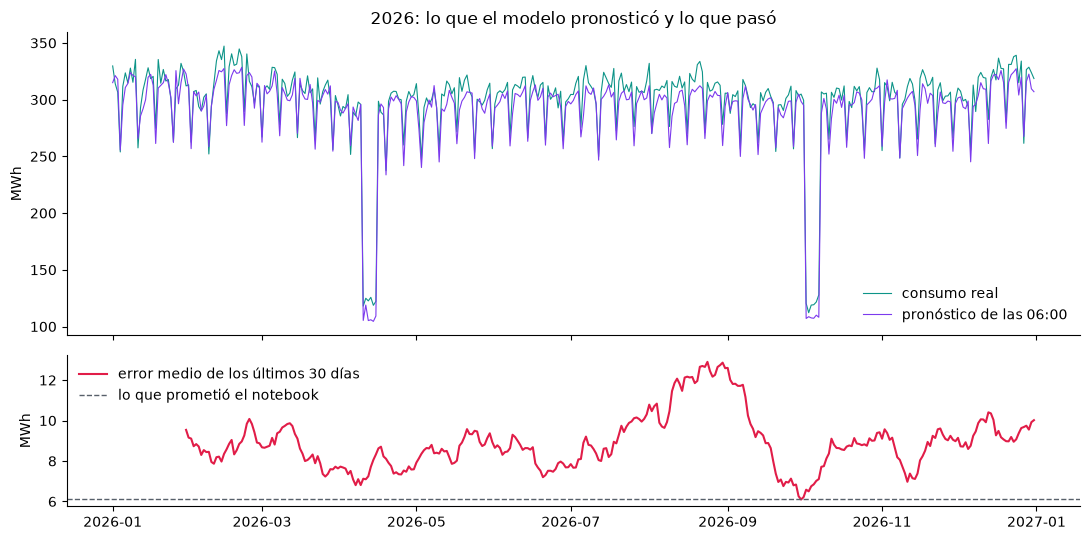

,MAE
trimestre,
1,8.62
2,8.15
3,9.76
4,9.41


In [7]:
error = (y_2026 - pred_2026).abs()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, height_ratios=[2, 1])
ax1.plot(fechas_2026, y_2026, lw=0.8, color=TURQUESA, label="consumo real")
ax1.plot(fechas_2026, pred_2026, lw=0.8, color=VIOLETA, label="pronóstico de las 06:00")
ax1.set_ylabel("MWh")
ax1.set_title("2026: lo que el modelo pronosticó y lo que pasó")
ax1.legend(frameon=False, loc="lower right")
ax2.plot(fechas_2026, error.rolling(30).mean(), color=ROSA, label="error medio de los últimos 30 días")
ax2.axhline(mae_prometido, color=GRIS, ls="--", lw=1, label="lo que prometió el notebook")
ax2.set_ylabel("MWh")
ax2.legend(frameon=False, loc="upper left")
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

error.groupby(fechas_2026.dt.quarter.to_numpy()).mean().round(2).rename_axis("trimestre").to_frame("MAE")

El error de 2026 es casi un 50 % mayor que el prometido. La curva roja toca la línea de la promesa un solo día, a fines de septiembre, y el segundo semestre es peor que el primero.

**Observación (un bosque no extrapola).** Cada árbol de un random forest predice el promedio de los consumos de entrenamiento que caen en una de sus hojas, y el bosque promedia sus árboles. Entonces cada predicción es un promedio ponderado de consumos de entrenamiento, y queda entre el mínimo y el máximo de la historia. La planta, en cambio, sube 7,3 MWh por año.

In [8]:
print(f"Máximo de la historia:           {y.max():.1f} MWh")
print(f"Máximo pronosticado en 2026:     {pred_2026.max():.1f} MWh")
print(f"Días de 2026 sobre el máximo de la historia: {(y_2026 > y.max()).sum()}")

Máximo de la historia:           340.1 MWh
Máximo pronosticado en 2026:     328.5 MWh
Días de 2026 sobre el máximo de la historia: 5


## 5. Cuatro fallas

### 5.1 No se repite

La celda de la sección 3 da un número distinto cada vez que se corre. Hay dos fuentes de azar: `train_test_split` elige al azar los días de prueba, y `RandomForestRegressor` elige al azar las muestras de cada árbol (*bootstrap*) y el orden en que prueba las features en cada corte, que decide los empates. Sin semillas, cada corrida es otro experimento. Con el bosque fijo, basta cambiar qué días quedan en prueba:

In [9]:
for semilla in range(6):
    X_e, X_p, y_e, y_p = train_test_split(X, y, test_size=0.2, random_state=semilla)
    m = RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1).fit(X_e, y_e)
    print(f"partición {semilla}:  MAE {mean_absolute_error(y_p, m.predict(X_p)):.2f}")

partición 0:  MAE 6.10


partición 1:  MAE 5.96


partición 2:  MAE 6.05


partición 3:  MAE 6.84


partición 4:  MAE 6.59


partición 5:  MAE 6.06


Es el mismo modelo con los mismos datos, y la promesa va de 5,96 a 6,84 según qué días tocaron en prueba. Si dos personas comparan dos modelos, cada una con su partición, pueden elegir el peor.

Fijar las semillas es la parte fácil, y no basta: una actualización de scikit-learn, un dato corregido en la tabla o un hiperparámetro cambiado en una celda también cambian el modelo. La **lección 2** agrega lo que falta para que dos corridas den el mismo modelo: versiones fijas, la huella de los datos y la configuración fuera del código.

### 5.2 La partición al azar mira el futuro

<img src="https://b3njjaman.github.io/MLOps-en-Azure/imagenes/diagramas/modulo-1/particiones.svg" alt="Quince días seguidos en dos filas. En la partición aleatoria, los días de prueba 3, 8 y 12 quedan salpicados entre días de entrenamiento, y el día de prueba 8 tiene al 7 y al 9 en entrenamiento: el modelo vio el día siguiente. En la partición temporal, los días 1 a 12 son de entrenamiento y los días 13 a 15 de prueba. Con la historia de la planta, la aleatoria promete MAE 6,1 y la temporal mide 8,1" width="760">

Con la partición al azar, cada vecino de un día de prueba queda en entrenamiento con probabilidad cercana a 0,8, así que casi todos los días de prueba tienen al menos uno. El vecino siguiente incluso trae, en su feature `consumo_ayer`, el consumo exacto del día de prueba.

In [10]:
vecino_siguiente = (X_pru.index + 1).isin(X_ent.index).mean()
print(f"Días de prueba cuyo día siguiente está en entrenamiento: {vecino_siguiente:.0%}")

fechas = df["fecha"].iloc[7:]
ent, pru = fechas < "2025-01-01", fechas >= "2025-01-01"
m = RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1).fit(X[ent], y[ent])
mae_temporal = mean_absolute_error(y[pru], m.predict(X[pru]))
print(f"Entrenando hasta 2024 y probando en 2025: MAE {mae_temporal:.2f} MWh")

Días de prueba cuyo día siguiente está en entrenamiento: 81%


Entrenando hasta 2024 y probando en 2025: MAE 8.12 MWh


En términos de la Propiedad 1.1 fallan las dos condiciones:

- **Independencia.** Por la Definición 1.3, $u_t$ y $u_{t+1}$ tienen correlación 0,6: conocer el día siguiente es conocer parte del error de hoy. La partición al azar le muestra al modelo al menos un vecino de casi cada día de prueba.
- **Distribución.** Los días de prueba salen del mismo período que los de entrenamiento. Los días en que se usa el modelo son posteriores a todo el entrenamiento, con una planta que ya subió su consumo.

La partición temporal respeta las dos: entrena con el pasado y prueba con lo que viene después, como en producción. Su 8,1 queda mucho más cerca del 9,0 de 2026 que el 6,1 de la aleatoria. La **lección 3** lo formaliza con el backtesting de origen móvil y mide cuánto pesa cada condición: los vecinos, poco; ver días posteriores a los de prueba, la mayor parte. También tiene una [simulación](https://b3njjaman.github.io/MLOps-en-Azure/complementarios/validacion.html) para ver cada esquema sobre la historia de la planta.

### 5.3 Lo que no existe a las 06:00

El modelo se entrenó con `temperatura`, la temperatura real. En 2026 recibe el pronóstico, que se equivoca con una desviación estándar de 2 °C. La feature tiene el mismo nombre en los dos momentos, pero no el mismo significado. Si se entrena con el dato que el modelo va a recibir:

In [11]:
X_pron = X.assign(temperatura=df["temperatura_pronostico"].iloc[7:])
modelo_pron = RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1).fit(X_pron, y)

print(f"2026, entrenado con la temperatura real:          MAE {mae_2026:.2f} MWh")
print(f"2026, entrenado con el pronóstico de temperatura: MAE {mean_absolute_error(y_2026, modelo_pron.predict(X_2026)):.2f} MWh")

2026, entrenado con la temperatura real:          MAE 8.99 MWh


2026, entrenado con el pronóstico de temperatura: MAE 8.50 MWh


El segundo caso es más común. Muchos notebooks codifican el día de la semana con `pd.get_dummies`, una columna por día. Con cuatro años de historia salen siete columnas. A las 06:00 llega un solo día, y `get_dummies` arma una sola:

In [12]:
X_dummies = pd.get_dummies(X, columns=["dia_semana"], dtype=int)
modelo_dummies = RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1).fit(X_dummies, y)
print("Columnas al entrenar:", list(X_dummies.columns), "\n")

hoy = X_2026.iloc[[0]]  # el 1 de enero de 2026, a las 06:00
try:
    modelo_dummies.predict(pd.get_dummies(hoy, columns=["dia_semana"], dtype=int))
except ValueError as falla:
    print(f"{type(falla).__name__}: {falla}")

Columnas al entrenar: ['produccion', 'temperatura', 'consumo_ayer', 'consumo_semana_pasada', 'dia_semana_0', 'dia_semana_1', 'dia_semana_2', 'dia_semana_3', 'dia_semana_4', 'dia_semana_5', 'dia_semana_6'] 

ValueError: The feature names should match those that were passed during fit.
Feature names seen at fit time, yet now missing:
- dia_semana_0
- dia_semana_1
- dia_semana_2
- dia_semana_4
- dia_semana_5
- ...



Los dos casos son la misma falla vista desde dos lados: la transformación que produce $x_t$ no es la misma al entrenar y al pronosticar. Se llama *training-serving skew*. El primero no avisa y cuesta precisión; el segundo, por suerte, rompe. La **lección 4** la resuelve con una sola transformación, guardada junto al modelo, que calcula las features en los dos momentos y solo con datos de $\mathcal{I}_t$.

### 5.4 Nada lo prueba

El modelo confía en lo que recibe. Supongamos que el 10 de febrero de 2026 el sistema de medición empieza a reportar en kWh en vez de MWh:

In [13]:
dia = X_2026.iloc[[40]].copy()  # el 10 de febrero de 2026
print(f"Consumo real del día:                 {y_2026.iloc[40]:.1f} MWh")
print(f"Pronóstico con los datos correctos:   {modelo.predict(dia)[0]:.1f} MWh")

dia["consumo_ayer"] = dia["consumo_ayer"] * 1000  # el medidor ahora reporta kWh
print(f"Pronóstico con el consumo de ayer en kWh: {modelo.predict(dia)[0]:.1f} MWh")

Consumo real del día:                 314.7 MWh


Pronóstico con los datos correctos:   309.1 MWh


Pronóstico con el consumo de ayer en kWh: 323.1 MWh


El consumo de ayer llegó mil veces más grande, y el pronóstico subió solo 14 MWh, a un valor que no llama la atención: por la Observación de la sección 4, un bosque no sale del rango de la historia. No hay error ni advertencia. Lo mismo pasa si a la tabla le falta un día: `shift(1)` toma el consumo de anteayer como si fuera el de ayer.

In [14]:
sin_un_dia = serie[serie["fecha"] != "2026-03-10"].reset_index(drop=True)  # se perdió el 10 de marzo
consumo_ayer = sin_un_dia["consumo"].shift(1)
el_11 = sin_un_dia["fecha"] == "2026-03-11"

print(f"consumo_ayer del 11 de marzo:  {consumo_ayer[el_11].iloc[0]:.1f} MWh")
print(f"consumo real del 10 de marzo:  {serie.loc[serie['fecha'] == '2026-03-10', 'consumo'].iloc[0]:.1f} MWh")
print(f"consumo real del 9 de marzo:   {serie.loc[serie['fecha'] == '2026-03-09', 'consumo'].iloc[0]:.1f} MWh")

consumo_ayer del 11 de marzo:  318.0 MWh
consumo real del 10 de marzo:  314.3 MWh
consumo real del 9 de marzo:   318.0 MWh


En los dos casos el pronóstico sale a tiempo, tiene un valor razonable y está calculado con datos equivocados. Esto lo atrapan las pruebas automáticas: de los datos (rangos, unidades, fechas seguidas), de las features y del modelo. Es la **lección 5**.

## 6. Qué significa estar en producción

Ninguna de las cuatro fallas es un error de programación: cada celda hace lo que dice. Son fallas de un modelo construido para responder una vez, en un notebook, y no para responder todos los días.

<img src="https://b3njjaman.github.io/MLOps-en-Azure/imagenes/diagramas/modulo-1/notebook-y-pipeline.svg" alt="A la izquierda, un notebook con seis celdas cuyos números de ejecución están fuera de orden: 3, 7, 5, 8, 6 y 9. A la derecha, un pipeline: datos v3, validar (lección 5), features (lección 4), entrenar (lección 2), evaluar (lección 3) y el modelo v7 registrado (módulo 2). La animación marca las celdas 7 y 5, que corrieron fuera de orden, y después recorre el pipeline paso a paso" width="760">

**Definición 1.6 (modelo en producción).** En este curso, un modelo está en producción cuando cumple cinco condiciones:

1. **Reproducible.** Con el mismo código, los mismos datos y la misma configuración, cualquiera obtiene el mismo modelo.
2. **Evaluado como se usa.** Su error se estima con días posteriores a los de entrenamiento y con la información que habrá al pronosticar.
3. **Una sola transformación.** Las features se calculan con la misma función al entrenar y al pronosticar, y solo con datos de $\mathcal{I}_t$.
4. **Probado.** Pruebas automáticas rechazan los datos y los modelos rotos antes de que lleguen a la decisión.
5. **Registrado y observado.** Cada modelo tiene registrados su versión, sus datos y sus métricas, y su error se mide cada día con el consumo real.

| Falla | Condición | Dónde se resuelve |
|---|---|---|
| 5.1 No se repite | Reproducible | Lección 2 |
| 5.2 La partición al azar mira el futuro | Evaluado como se usa | Lección 3 |
| 5.3 Lo que no existe a las 06:00 | Una sola transformación | Lección 4 |
| 5.4 Nada lo prueba | Probado | Lección 5 |
| El error de 2026 se supo recién al final | Registrado y observado | Módulos 2 y 6 |

## 7. En Azure

El curso usa Azure Machine Learning. Cada condición de la Definición 1.6 tiene una pieza de Azure ML que la implementa, y los módulos del curso las van usando una por una:

| Condición | En Azure Machine Learning | Módulo |
|---|---|---|
| Reproducible | *Environments* (una imagen de Docker con las dependencias fijas) y *data assets* con versión | 1 y 3 |
| Evaluado como se usa | *Pipeline jobs* con un paso de evaluación y una compuerta antes de registrar | 3 |
| Una sola transformación | Un pipeline de scikit-learn o un modelo de MLflow que lleva la transformación adentro | 1 y 2 |
| Probado | Pruebas en GitHub Actions y un paso de validación de datos dentro del pipeline | 3 y 5 |
| Registrado | El registro de modelos con MLflow, en el workspace o en un registry compartido | 2 |
| Pronosticado a las 06:00 | Un *batch endpoint* que se invoca cada mañana | 4 |
| Observado | *Model monitoring* y el error calculado con el consumo real del día siguiente | 6 |

Este módulo corre entero en el notebook, sin suscripción. Cada lección termina mostrando cómo se ve en Azure lo que construyó.

## Ejercicios

**Ejercicio 1 (la línea base por trimestre).** Calcular el MAE de la línea base en cada trimestre de 2026 y compararlo con el del modelo. ¿En qué trimestre le gana menos el modelo, y por qué?

*Pista:* la línea base repite el consumo de hace siete días. ¿Qué le pasa en la semana en que empieza una parada, y en la semana en que termina?

<details>
<summary>Solución</summary>

```python
error_base = (y_2026 - X_2026["consumo_semana_pasada"]).abs()
trimestre = fechas_2026.dt.quarter.to_numpy()
pd.DataFrame(
    {"modelo": error.groupby(trimestre).mean(), "linea_base": error_base.groupby(trimestre).mean()}
).round(2)
```

| trimestre | modelo | línea base |
|---|---|---|
| 1 | 8,62 | 13,89 |
| 2 | 8,15 | 29,40 |
| 3 | 9,76 | 9,53 |
| 4 | 9,41 | 32,67 |

La línea base pierde mucho en el segundo y el cuarto trimestre, que tienen las paradas de abril y de octubre: con `shift(7)`, los seis días de la parada repiten días normales, y del segundo al séptimo día después de la parada se repiten días parados. Son doce días por parada, con errores de más de 100 MWh. En el tercer trimestre no hay paradas, y la línea base **le gana** al modelo. El contrato dice que si el modelo no le gana a la línea base, no se usa. En el año completo le gana, pero un contrato más exigente podría pedirlo trimestre a trimestre.

</details>

**Ejercicio 2 (descomponer la brecha).** La diferencia entre el 6,1 prometido y el 9,0 de 2026 se puede repartir en tres pasos: de la partición aleatoria a la temporal; de la temperatura real al pronóstico, con el mismo modelo y los mismos días de prueba; y de 2025 a 2026. Medir cada paso.

<details>
<summary>Solución</summary>

```python
X_pru_2025 = X[pru].assign(temperatura=df["temperatura_pronostico"].iloc[7:][pru])
mae_2025_pron = mean_absolute_error(y[pru], m.predict(X_pru_2025))
print(f"partición aleatoria:            {mae_prometido:.2f}")
print(f"temporal, temperatura real:     {mae_temporal:.2f}")
print(f"temporal, pronóstico:           {mae_2025_pron:.2f}")
print(f"2026:                           {mae_2026:.2f}")
```

La partición explica la mayor parte: de 6,10 a 8,12. Cambiar la temperatura real por el pronóstico casi no mueve el error de 2025, porque el consumo de ayer ya trae buena parte de la información del clima. El paso de 2025 a 2026 suma cerca de 0,9: el modelo de 2026 entrenó con un año más, pero la planta siguió subiendo, y un bosque no extrapola.

</details>

**Ejercicio 3 (elegir con la prueba también es mirarla).** Entrenar un bosque para cada combinación de `max_depth` en $\{3, 5, 8, 12, \text{None}\}$ y `min_samples_leaf` en $\{1, 5, 20, 50\}$ con la partición `random_state=0`, y quedarse con el de menor MAE de prueba. Ningún modelo vio los días de prueba. Demostrar que, aun así, el MAE del elegido es una estimación optimista: si $f_1, \dots, f_m$ son fijos,

$$\mathbb{E}\Big[\min_j \widehat{R}_P(f_j)\Big] \le \min_j R(f_j).$$

<details>
<summary>Solución</summary>

Para cada $k$, $\min_j \widehat{R}_P(f_j) \le \widehat{R}_P(f_k)$. Tomando esperanza y usando la Propiedad 1.1, $\mathbb{E}\big[\min_j \widehat{R}_P(f_j)\big] \le R(f_k)$ para todo $k$, y por lo tanto también para el mínimo. La desigualdad suele ser estricta: el mínimo elige al modelo que tuvo suerte con esos días de prueba.

```python
import itertools

resultados = []
for profundidad, hoja in itertools.product([3, 5, 8, 12, None], [1, 5, 20, 50]):
    m = RandomForestRegressor(
        n_estimators=200, max_depth=profundidad, min_samples_leaf=hoja, random_state=0, n_jobs=-1
    ).fit(X_ent, y_ent)
    resultados.append((mean_absolute_error(y_pru, m.predict(X_pru)), profundidad, hoja))
min(resultados, key=lambda r: r[0])  # MAE 6,05 con max_depth=None y min_samples_leaf=5
```

El elegido promete 6,05; reentrenado con los cuatro años, en 2026 entrega 9,11. Usar los días de prueba para elegir los convierte en parte del entrenamiento. Por eso, para elegir, se separa un conjunto de validación, y la prueba se mira una sola vez, al final.

</details>

**Ejercicio 4 (un modelo que sí extrapola).** La Observación de la sección 4 dice que el bosque no puede seguir la tendencia. Probar dos arreglos: agregar el número de día $t$ como feature, y ajustar primero una recta $\beta_0 + \beta_1 t$ con regresión lineal y entrenar el bosque sobre los residuos $y_t - (\beta_0 + \beta_1 t)$. ¿Cuál funciona en 2026, y por qué el otro no?

<details>
<summary>Solución</summary>

```python
from sklearn.linear_model import LinearRegression

t = (df["fecha"].iloc[7:] - pd.Timestamp("2022-01-01")).dt.days.to_numpy().reshape(-1, 1)
t_2026 = (fechas_2026 - pd.Timestamp("2022-01-01")).dt.days.to_numpy().reshape(-1, 1)

con_t = RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1).fit(X.assign(t=t.ravel()), y)
print(f"bosque con t:          {mean_absolute_error(y_2026, con_t.predict(X_2026.assign(t=t_2026.ravel()))):.2f}")

recta = LinearRegression().fit(t, y)
residuos = RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1).fit(X, y - recta.predict(t))
pred = recta.predict(t_2026) + residuos.predict(X_2026)
print(f"recta + bosque:        {mean_absolute_error(y_2026, pred):.2f}   pendiente {recta.coef_[0]:.4f} MWh/día")
```

Con $t$ como feature el error baja a 7,26, pero el bosque sigue acotado: para todos los días de 2026, $t$ es mayor que cualquier $t$ de entrenamiento, y en los cortes sobre $t$ caen del mismo lado que los últimos días de 2025. La recta sí extrapola: estima una pendiente de 0,0188 MWh por día, cerca del 0,02 de la Definición 1.3, y el bosque aprende lo que queda (aunque el consumo de ayer y el de la semana pasada, que entran como features, todavía traen la tendencia). El error de 2026 baja a 6,41. Es un ejemplo de por qué conocer el proceso que genera los datos ayuda a elegir el modelo.

</details>

**Siguiente:** la lección 2 hace que el modelo se pueda repetir: semillas, versiones fijas, la huella de los datos y una configuración fuera del código.